In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("diamonds.csv")
df.head(10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [3]:
df.shape

(53940, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [5]:
round(df.describe(),1)

,carat,depth,table,price,x,y,z
count,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0
mean,0.8,61.7,57.5,3932.8,5.7,5.7,3.5
std,0.5,1.4,2.2,3989.4,1.1,1.1,0.7
min,0.2,43.0,43.0,326.0,0.0,0.0,0.0
25%,0.4,61.0,56.0,950.0,4.7,4.7,2.9
50%,0.7,61.8,57.0,2401.0,5.7,5.7,3.5
75%,1.0,62.5,59.0,5324.2,6.5,6.5,4.0
max,5.0,79.0,95.0,18823.0,10.7,58.9,31.8


In [6]:
mean_x= round(df.loc[df["x"] != 0, "x"].mean(),2)
# print(mean_x)
df["x"] = df["x"].replace(0.0, mean_x)

In [7]:
mean_y= round(df.loc[df["y"] != 0, "y"].mean(),2)
# print(mean_y)
df["y"] = df["y"].replace(0.0, mean_y)

mean_z= round(df.loc[df["z"] != 0, "z"].mean(),2)
# print(mean_z)
df["z"] = df["z"].replace(0.0, mean_z)

In [8]:
round(df.describe(),1)

,carat,depth,table,price,x,y,z
count,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0,53940.0
mean,0.8,61.7,57.5,3932.8,5.7,5.7,3.5
std,0.5,1.4,2.2,3989.4,1.1,1.1,0.7
min,0.2,43.0,43.0,326.0,3.7,3.7,1.1
25%,0.4,61.0,56.0,950.0,4.7,4.7,2.9
50%,0.7,61.8,57.0,2401.0,5.7,5.7,3.5
75%,1.0,62.5,59.0,5324.2,6.5,6.5,4.0
max,5.0,79.0,95.0,18823.0,10.7,58.9,31.8


In [9]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [10]:
df.duplicated().sum()

146

In [11]:
df[df.duplicated()]


,carat,cut,color,clarity,depth,table,price,x,y,z
1005,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
2025,1.52,Good,E,I1,57.3,58.0,3105,7.53,7.42,4.28
...,...,...,...,...,...,...,...,...,...,...
47969,0.52,Ideal,D,VS2,61.8,55.0,1919,5.19,5.16,3.20
49326,0.51,Ideal,F,VVS2,61.2,56.0,2093,5.17,5.19,3.17
49557,0.71,Good,F,SI2,64.1,60.0,2130,5.73,5.74,3.54
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203,5.19,5.17,3.17


In [12]:
df= df.drop_duplicates()

In [13]:
df.duplicated().any()

False

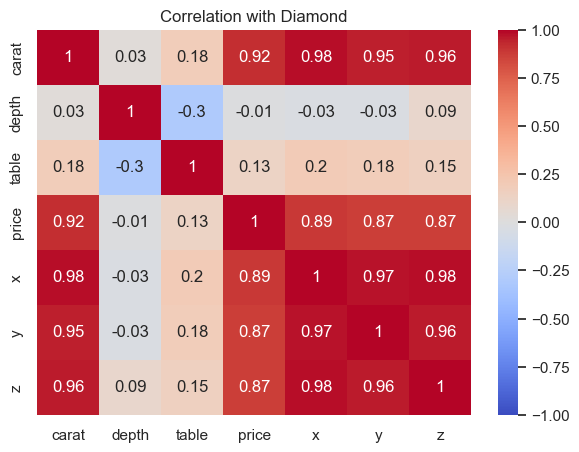

In [14]:
cols =["carat", "depth", "table","price", "x","y","z"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation with Diamond")
plt.show()

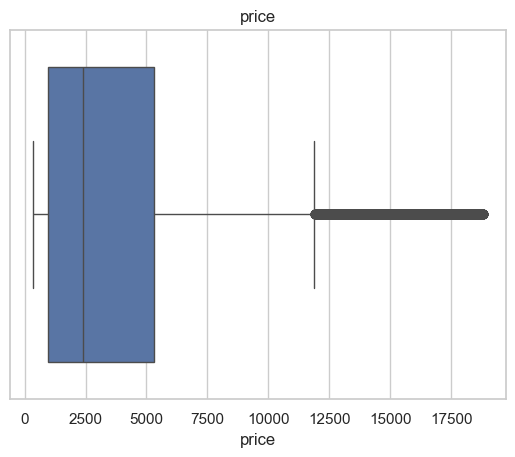

In [15]:
sns.boxplot(data=df, x="price")
plt.title("price")
plt.show()

In [16]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Above", round(high, 1), "is an outlier")

outliers = df[df["price"] > high]
print("Number of outliers:", len(outliers))
outliers.sort_values("price", ascending=False).head()

Q1: 951.0  Q3: 5326.75  IQR: 4375.8
Above 11890.4 is an outlier
Number of outliers: 3523


,carat,cut,color,clarity,depth,table,price,x,y,z
27749,2.29,Premium,I,VS2,60.8,60.0,18823,8.50,8.47,5.16
27748,2.00,Very Good,G,SI1,63.5,56.0,18818,7.90,7.97,5.04
27747,1.51,Ideal,G,IF,61.7,55.0,18806,7.37,7.41,4.56
27746,2.07,Ideal,G,SI2,62.5,55.0,18804,8.20,8.13,5.11
27745,2.00,Very Good,H,SI1,62.8,57.0,18803,7.95,8.00,5.01


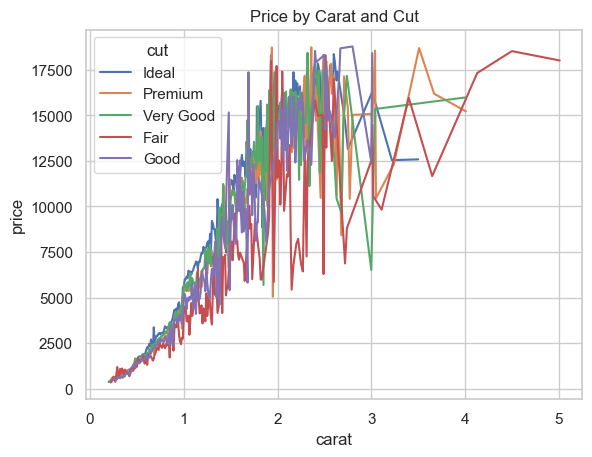

In [17]:
# Same carat, different cut
result = df.groupby(
    ["carat", "cut"]
)["price"].mean().reset_index()

sns.lineplot(
    data=result,
    x="carat",
    y="price",
    hue="cut"
)

plt.title("Price by Carat and Cut")
plt.show()

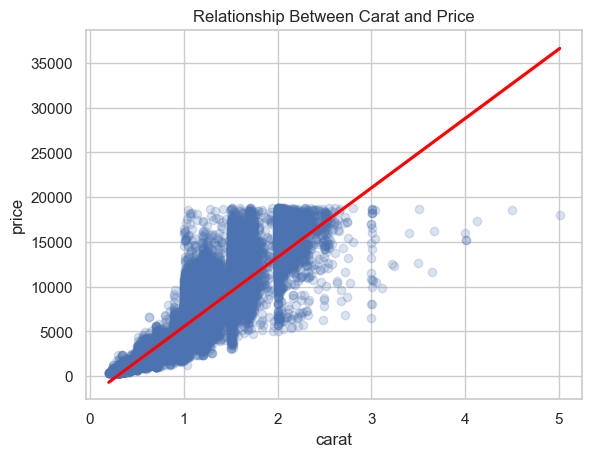

In [18]:


sns.regplot(data=df, x="carat", y="price",
            scatter_kws={"alpha": 0.2},
            line_kws={"color": "red"})

plt.title("Relationship Between Carat and Price")
plt.show()

Compare cut for the same carat

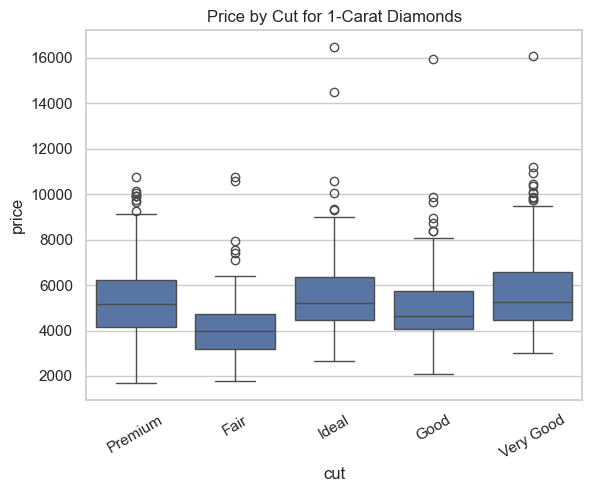

In [19]:
sns.boxplot(data=df[df["carat"] == 1.0],
            x="cut", y="price")

plt.title("Price by Cut for 1-Carat Diamonds")
plt.xticks(rotation=30)
plt.show()

Step 2: Compare color and clarity

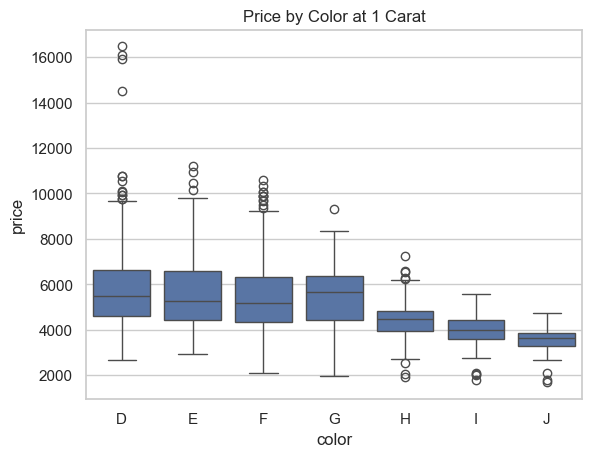

In [20]:
#color vs price
sns.boxplot(data=df[df["carat"] == 1.0],
            x="color", y="price",
            order=["D", "E", "F", "G", "H", "I", "J"])

plt.title("Price by Color at 1 Carat")
plt.show()

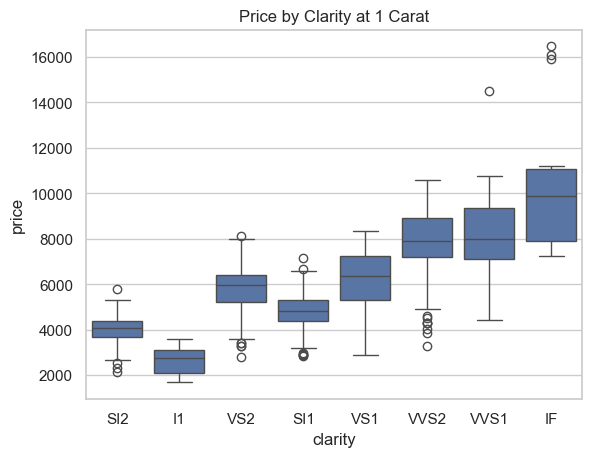

In [21]:
#clarity vs price
sns.boxplot(data=df[df["carat"] == 1.0],
            x="clarity", y="price")

plt.title("Price by Clarity at 1 Carat")
plt.show()

Compare quality while controlling for carat

In [22]:

import statsmodels.formula.api as smf

model = smf.ols(
    "np.log(price) ~ carat + I(carat**2) + C(cut) + C(color) + C(clarity)",
    data=df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          np.log(price)   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                 1.072e+05
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:23   Log-Likelihood:                 21354.
No. Observations:               53794   AIC:                        -4.267e+04
Df Residuals:                   53774   BIC:                        -4.249e+04
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               4.6729    

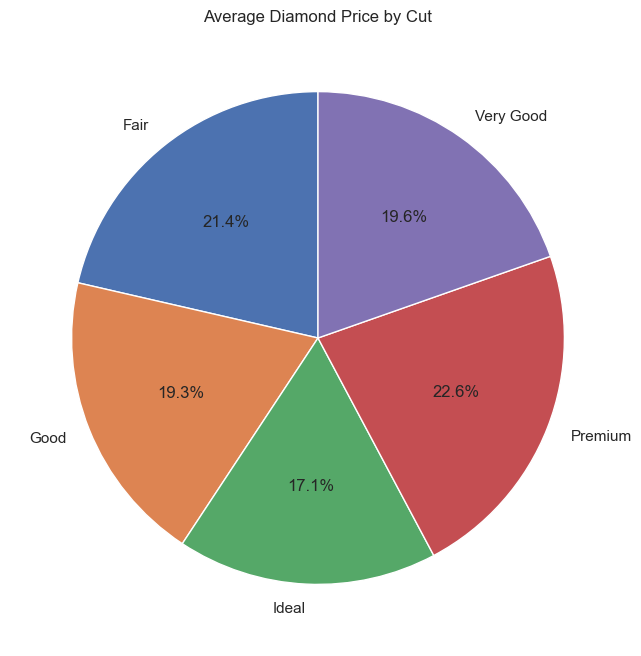

In [23]:
# Same carat, different cut
result = df.groupby("cut")["price"].mean().reset_index()

plt.figure(figsize=(8, 8))

plt.pie(
    result["price"],
    labels=result["cut"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Average Diamond Price by Cut")
plt.show()